In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import os
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("../data/Mall_Customers.csv")

In [3]:
print(df.shape)

(200, 5)


In [4]:
print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [6]:
print(df.describe())

       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


In [7]:
print(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


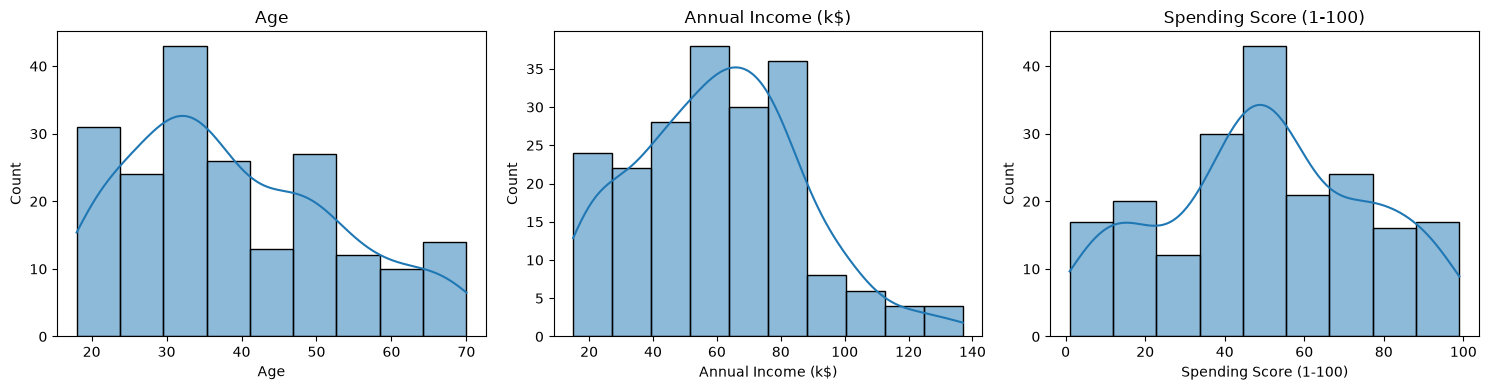

In [8]:
cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
fig , axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, cols):
    sns.histplot(df[col], kde=True, ax = ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

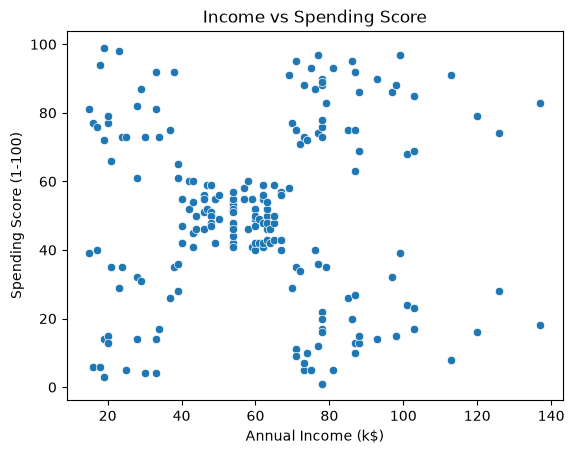

In [9]:
sns.scatterplot(
    x = "Annual Income (k$)",
    y = "Spending Score (1-100)",
    data = df
)
plt.title("Income vs Spending Score")
plt.show()

In [10]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled.mean(axis=0))
print(X_scaled.std(axis=0))

[-2.13162821e-16 -1.46549439e-16]
[1. 1.]


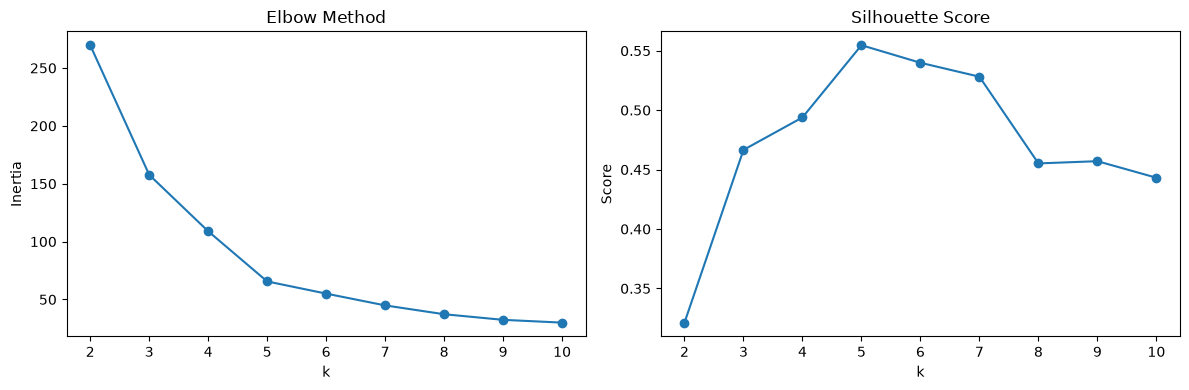

In [11]:
inertias = []
sil_scores = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias .append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_range, inertias, marker = "o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_range, sil_scores, marker = "o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Score")


plt.tight_layout()
plt.show()

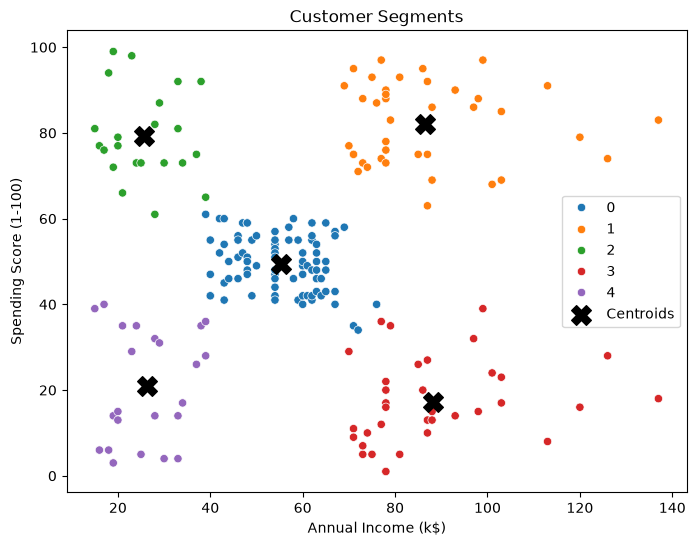

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [12]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x = "Annual Income (k$)",
    y = "Spending Score (1-100)",
    hue = "Cluster",
    palette = "tab10",
    data=df
)

plt.scatter(centers[:, 0], centers[:,1], c = "black", s = 200, marker = "X", label="Centroids")
plt.title("Customer Segments")
plt.legend()
plt.show()

print(df["Cluster"].value_counts().sort_index())

In [13]:
print(df.groupby("Cluster")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1))

          Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                  
0        42.7                55.3                    49.5
1        32.7                86.5                    82.1
2        25.3                25.7                    79.4
3        41.1                88.2                    17.1
4        45.2                26.3                    20.9


In [14]:
summary = df.groupby("Cluster").agg(
    Count = ("CustomerID", "count"),
    Age = ("Age", "mean"),
    Income = ("Annual Income (k$)", "mean"),
    Spending = ("Spending Score (1-100)", "mean"), 
).round(1)

print(summary)

         Count   Age  Income  Spending
Cluster                               
0           81  42.7    55.3      49.5
1           39  32.7    86.5      82.1
2           22  25.3    25.7      79.4
3           35  41.1    88.2      17.1
4           23  45.2    26.3      20.9


In [15]:
names = {
    0: "Standard",
    1: "Premium Target",
    2: "Young Spenders",
    3: "Careful Savers",
    4: "Budget Conscious",
}
df["Segment"] = df["Cluster"].map(names)
print(df["Segment"].value_counts())

Segment
Standard            81
Premium Target      39
Careful Savers      35
Budget Conscious    23
Young Spenders      22
Name: count, dtype: int64


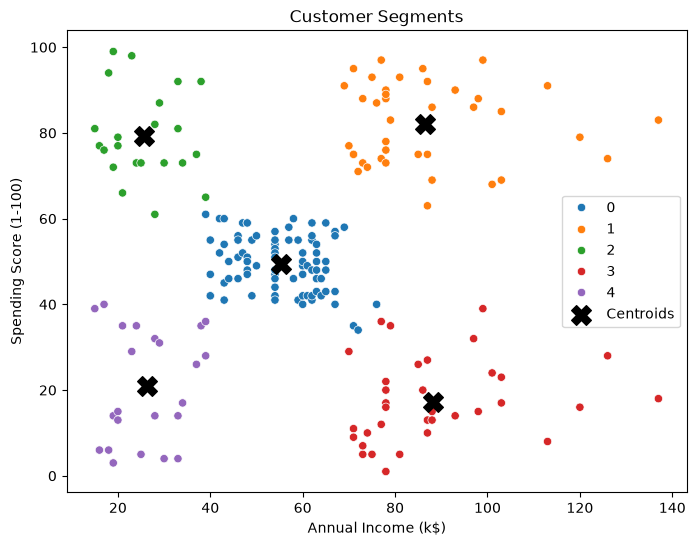

In [16]:
os.makedirs("../outputs/figures", exist_ok=True)

df.to_csv("../outputs/customers_with_clusters.csv", index = False)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x = "Annual Income (k$)",
    y = "Spending Score (1-100)",
    hue = "Cluster",
    palette = "tab10",
    data= df
)

plt.scatter(centers[:, 0], centers[:,1], c = "black", s = 200, marker = "X", label="Centroids")
plt.title("Customer Segments")
plt.legend()
plt.savefig("../outputs/figures/clusters.png", dpi = 150, bbox_inches="tight")
plt.show()